        Datetime  Temperature  Humidity  WindSpeed  GeneralDiffuseFlows  \
0  1/1/2017 0:00        6.559      73.8      0.083                0.051   
1  1/1/2017 0:10        6.414      74.5      0.083                0.070   
2  1/1/2017 0:20        6.313      74.5      0.080                0.062   
3  1/1/2017 0:30        6.121      75.0      0.083                0.091   
4  1/1/2017 0:40        5.921      75.7      0.081                0.048   

   DiffuseFlows  PowerConsumption_Zone1  PowerConsumption_Zone2  \
0         0.119             34055.69620             16128.87538   
1         0.085             29814.68354             19375.07599   
2         0.100             29128.10127             19006.68693   
3         0.096             28228.86076             18361.09422   
4         0.085             27335.69620             17872.34043   

   PowerConsumption_Zone3  
0             20240.96386  
1             20131.08434  
2             19668.43373  
3             18899.27711  
4     

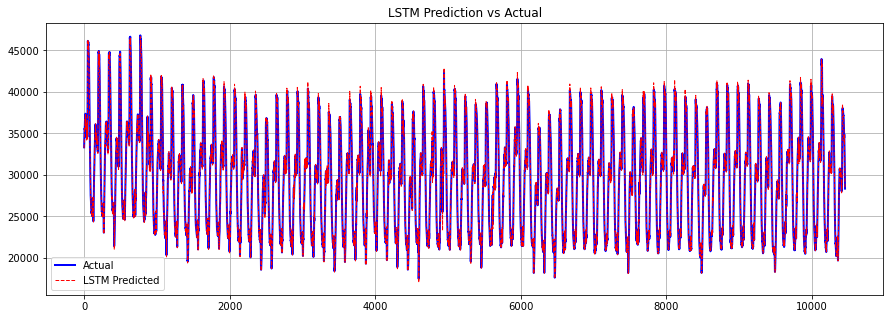

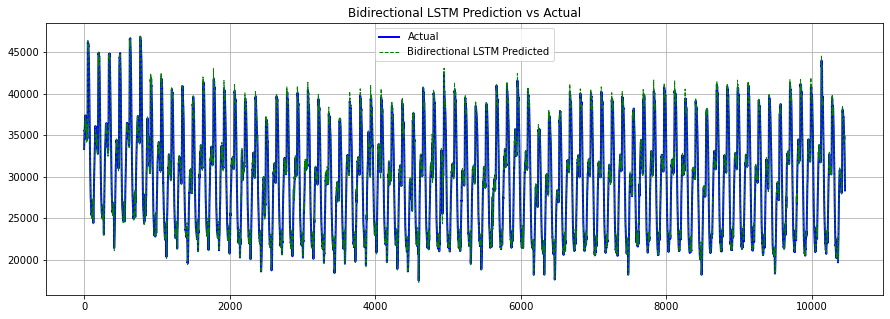

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# 1. Load and sort data
csv_path = r"powerconsumption.csv"
df = pd.read_csv(csv_path)

print(df.head())
print(df.info())
print(df.columns)
print(df.isnull().sum())

df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime").reset_index(drop=True)

# Extract target series
values = df[["PowerConsumption_Zone1"]].dropna().values

# 2. Chronological train/test split & scaler fit on train only
train_size = int(len(values) * 0.8)
train_raw = values[:train_size]
test_raw = values[train_size:]

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)


# 3. Create sliding windows
def create_sequences(data, lookback=30):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i : i + lookback])
        y.append(data[i + lookback])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


lookback = 30
X_train, y_train = create_sequences(train_scaled, lookback)
X_test, y_test = create_sequences(test_scaled, lookback)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)


def make_callbacks():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            verbose=1,
        ),
    ]


# 4. Unidirectional LSTM
lstm_model = Sequential([
    LSTM(64, input_shape=(lookback, 1)),
    Dense(32, activation="relu"),
    Dense(1),
])

lstm_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
lstm_model.summary()

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=32,
    callbacks=make_callbacks(),
    verbose=1,
)

loss_lstm, mae_lstm = lstm_model.evaluate(X_test, y_test, verbose=0)
print(f"LSTM -> Loss (MSE): {loss_lstm:.6f}, MAE: {mae_lstm:.6f}")

# 5. Bidirectional LSTM
bilstm_model = Sequential([
    Bidirectional(LSTM(64), input_shape=(lookback, 1)),
    Dense(32, activation="relu"),
    Dense(1),
])

bilstm_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
bilstm_model.summary()

history_bilstm = bilstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=32,
    callbacks=make_callbacks(),
    verbose=1,
)

loss_bilstm, mae_bilstm = bilstm_model.evaluate(X_test, y_test, verbose=0)
print(f"BiLSTM -> Loss (MSE): {loss_bilstm:.6f}, MAE: {mae_bilstm:.6f}")

# 6. Comparison table
comparison = pd.DataFrame({
    "Model": ["LSTM", "Bidirectional LSTM"],
    "Loss": [loss_lstm, loss_bilstm],
    "MAE": [mae_lstm, mae_bilstm],
})
print(comparison)

# 7. Inverse-transform predictions and plot
actual = scaler.inverse_transform(y_test)
pred_lstm = scaler.inverse_transform(lstm_model.predict(X_test, verbose=0))
pred_bilstm = scaler.inverse_transform(bilstm_model.predict(X_test, verbose=0))

plt.figure(figsize=(15, 5))
plt.plot(actual, label="Actual", color="blue", linewidth=2)
plt.plot(pred_lstm, label="LSTM Predicted", color="red", linestyle="--", linewidth=1)
plt.legend()
plt.title("LSTM Prediction vs Actual")
plt.grid(True)
plt.show()

plt.figure(figsize=(15, 5))
plt.plot(actual, label="Actual", color="blue", linewidth=2)
plt.plot(pred_bilstm, label="Bidirectional LSTM Predicted", color="green", linestyle="--", linewidth=1)
plt.legend()
plt.title("Bidirectional LSTM Prediction vs Actual")
plt.grid(True)
plt.show()